In [14]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [15]:
#import modules and load the data
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute


df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [16]:
#Prepare the data
df = df.dropna() #remove missings
y = df['charges'] #select Target
X = df.drop(['charges','sex'],axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) #Turn sex, smoker, region, and death into dummy variables


In [17]:
#Prediction with all features
#define the cross-validation

#predict with linear regression
lm = LinearRegression()
lmscores = cross_val_score(lm, X, y, #these define the type of model, features, and target
                           scoring='neg_mean_absolute_error', #test using mean absolute deviation
                           cv=5) #use cross-validation with 5 folds


lmMAE = mean(absolute(lmscores)) #Calculate the overall mean absolute error
print('the average prediction error with full data is: %.0f' % lmMAE) #Print the result

the average prediction error with full data is: 4197


In [18]:
# Example with logistic regression

#load titanic data
titanic = pd.read_csv('titanic.csv')
titanic = titanic.dropna()
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,True


In [21]:
#prepare the data
from sklearn.preprocessing import MinMaxScaler

y= titanic['survived']
X = titanic.drop('survived',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True)

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

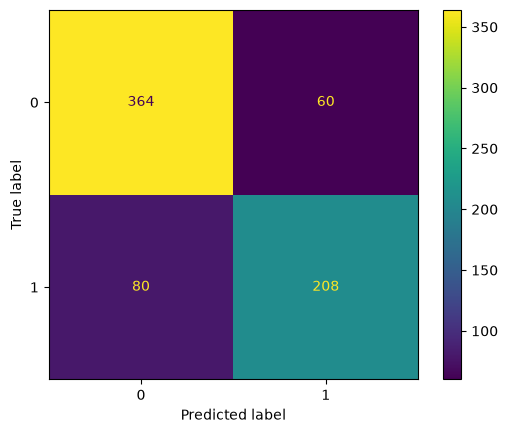

Accuracy: 0.8033707865168539
Precision: 0.7761194029850746
Recall: 0.7222222222222222
F1 Score: 0.7482014388489209


In [22]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

logreg = LogisticRegression() #Define the logistic regression function
y_pred = cross_val_predict(logreg, X, y, cv=5) #make the prediction with 5 folds

cm = confusion_matrix(y, y_pred) #Create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

#calculate metrics
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
f1 = f1_score(y, y_pred)

#print the metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)